In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
from pathlib import Path

if 'google.colab' in sys.modules:
    repo_name = "study-mikanos"
    repo_url = "https://github.com/miyayudai/study-mikanos.git"
    if not os.path.exists(f"/content/{repo_name}"):
        print(f"{repo_name} リポジトリをダウンロード中...")
        !git clone {repo_url} > /dev/null 2>&1

    print("必要な依存パッケージをインストール中...")
    %cd /content/{repo_name}
    !pip install -q -r requirements.txt
    !pip install -q -e .
    !cmake -B build -S .
    !cmake --build build

    print("作業ディレクトリを第1章へ移動中...")
    %cd /content/{repo_name}/1
    print("✅ 準備完了！このまま下のセルを実行して学習を開始できます。")
else:
    _repo_root = Path.cwd().parent if Path.cwd().name == '1' else Path.cwd()
    if str(_repo_root) not in sys.path:
        sys.path.insert(0, str(_repo_root))
    print("✅ ローカル環境で実行中: リポジトリルートを sys.path に設定しました。")


✅ ローカル環境で実行中: リポジトリルートを sys.path に設定しました。


# 第1章 PCの仕組みとハローワールド — 1.7 UEFI BIOSによる起動 (*Booting with UEFI BIOS*)

本節では、名著『**ゼロからのOS自作入門**』（内田公太 著）の **第1章 1.7「UEFI BIOSによる起動」** に基づき、なぜ PC の起動ファームウェアが半世紀近く続いた「**レガシー BIOS (Legacy BIOS)**」から「**UEFI (Unified Extensible Firmware Interface)**」へと世代交代したのか、その歴史的背景・ハードウェア動作モード・数理的制約、そして OS 開発者に与えた劇的な恩恵を徹底解剖します。

---

## 🎯 本節の学習目標と技術的動機

1. **レガシー BIOS と UEFI の決定的なアーキテクチャ差異の理解**:
   - 1981年の IBM PC 5150 から続く 16ビットリアルモード（Real Mode）起動の歴史的経緯と、UEFI による 64ビットロングモード（Long Mode / IA-32e）直接起動の対比。
2. **CPU動作モード昇格の過酷な道のりとその解消**:
   - レガシーブートにおける A20 ゲート解除、GDT（Global Descriptor Table）構築、32ビット保護モード、PAE、4階層ページング（PML4）構築の多段ステップと、UEFI がこれらを全自動で完了している恩恵。
3. **ディスクパーティショニング方式の数理的限界（MBR vs GPT）**:
   - わずか 512 バイトのブートセクタと 32-bit LBA アドレッシングによる **「2.0 TiBの壁」** の数理導出。
   - 64-bit LBA（**9.4 Zettabytes**）と 128-bit GUID、末尾バックアップによる高信頼性 GPT（*GUID Partition Table*）の構造解剖。
4. **UEFI システムサービスの2大分類**:
   - ブートサービス (*Boot Services*) とランタイムサービス (*Runtime Services*) の役割境界と、`ExitBootServices()` による OS カーネルへのメモリ完全委譲の仕組み。
5. **MikanOS が第1章からいきなり 64ビットでハローワールドできた理由**:
   - ブートローダ自作の最大の挫折ポイントを回避し、現代的な C++20 カーネル開発に集中できる技術的必然性の確立。


## 1. レガシー BIOS の歴史と 16ビットリアルモードの呪縛

### 1.1 IBM PC 5150 と Intel 8086 の遺産 (Heritage of the 1980s)

1981年に登場した IBM PC 5150 に搭載された CPU は、16ビットプロセッサ **Intel 8086**（クロック周波数 4.77 MHz）でした。
このとき ROM に焼き込まれていた基本入出力システムが **BIOS (*Basic Input/Output System*)** です。

当時の Intel 8086 は、アドレスバスが 20 本しかなく、アクセスできるメモリ空間は最大でもわずか **$2^{20} = 1\text{ MB}$**（そのうち OS やプログラムが使えるコンベンショナルメモリは $640\text{ KB}$ のみ）でした。
Intel は、16ビットのレジスタで 20ビットの物理アドレス（最大 1MB）を指定するため、**セグメント方式（Segment:Offset）** を採用しました。

$$\text{Linear Address} = (\text{Segment} \times 16) + \text{Offset} = (\text{Segment} \ll 4) + \text{Offset}$$

例えば、BIOS ブートセクタがロードされる物理アドレス `0x07C00` は、セグメント `0x0000`、オフセット `0x7C00` として表現されます。

### 1.2 A20 ゲート (A20 Gate) の歴史的ラップアラウンド問題

セグメント方式では、最大セグメント `0xFFFF` と最大オフセット `0xFFFF` を組み合わせると：

$$\text{Linear Address} = (0\text{xFFFF} \times 16) + 0\text{xFFFF} = 0\text{FFFF0} + 0\text{xFFFF} = 0\text{x10FFEF} \quad (1\text{MB} + 65519\text{ bytes})$$

となり、20ビットのアドレスバス（`0x00000` 〜 `0xFFFFF`）を 64KB 弱だけ超過します。
オリジナルの 8086 ではアドレスバスが 20 本しかないため、最上位ビット（21本目の線、すなわち **Bit 20**）が物理的に存在せず、`0x100000` は `0x000000` へと自動的に **ラップアラウンド（Wraparound）** していました。

ところが、次世代の **Intel 80286** ではアドレスバスが 24 本（16MB空間）に拡張されたため、このラップアラウンドが起きなくなりました。すると、8086 の「1MB境界でのメモリラップアラウンド挙動」に依存していた一部の MS-DOS ソフトウェアがクラッシュしてしまったのです。

IBM の技術者は後方互換性を保つため、キーボードコントローラ（Intel 8042）の空き出力ピンを利用して、**「Bit 20 の信号線を強制的に 0 に落とす論理積ゲート（A20 Gate）」** をマザーボードに組み込みました。
このため、レガシー PC で 1MB を超えるメモリ空間にアクセスするには、ブートローダが起動直後に**キーボードコントローラ I/O ポート（`0x64`, `0x60`）やファスト A20 ゲート（ポート `0x92`）を叩いて A20 ゲートを明示的に解除（Enable）しなければならない**という過酷な手続きが存在したのです。

### 1.3 MBR (Master Boot Record) の 512 バイト制限と 2TiB の壁

レガシー BIOS はストレージのパーティション構造やファイルシステム（FAT32 や ext4）を一切解釈できません。
ストレージの最先頭セクタ（LBA 0、わずか **512 バイト**）を物理メモリ `0x07C00` に読み込み、末尾 2 バイトがブートシグネチャ `0xAA55`（リトルエンディアンで `0x55, 0xAA`）であるかを確認して、`0x07C00` に無条件ジャンプするだけでした。

この 512 バイトの内訳は以下の通りです：
- **ブートストラップ機械語コード**: わずか **446 バイト**！
- **パーティションテーブル（4エントリ × 16バイト）**: **64 バイト**
- **ブートシグネチャ (`0x55, 0xAA`)**: **2 バイト**

わずか 446 バイトの機械語コードの中に、ファイルシステム（FAT32/ext4）のパーサや複雑なカーネルロード処理を詰め込むことは物理的に不可能です。
そのため、レガシーブートローダは**ディスクの特定セクタ番号（LBA）を生で直打ちして次段ローダ（Stage 2）をロードする多段ブートローダ構成**を余儀なくされていました。

さらに、MBR のパーティションテーブルにおけるセクタ番号（LBA）フィールドは **32 ビット** しかありません。
1セクタ 512 バイトの場合、アドレッシング可能な最大容量は：

$$\text{Max Capacity} = 2^{32} \times 512\text{ bytes} = 4,294,967,296 \times 512 = 2,199,023,255,552\text{ bytes} = 2.0\text{ TiB} \quad (2.199\text{ TB})$$

現代の 4TB や 8TB の大容量 HDD/SSD を MBR でフォーマットすると、2TiB を超える領域を認識できなくなるという **「2TiB の壁」** が発生します。


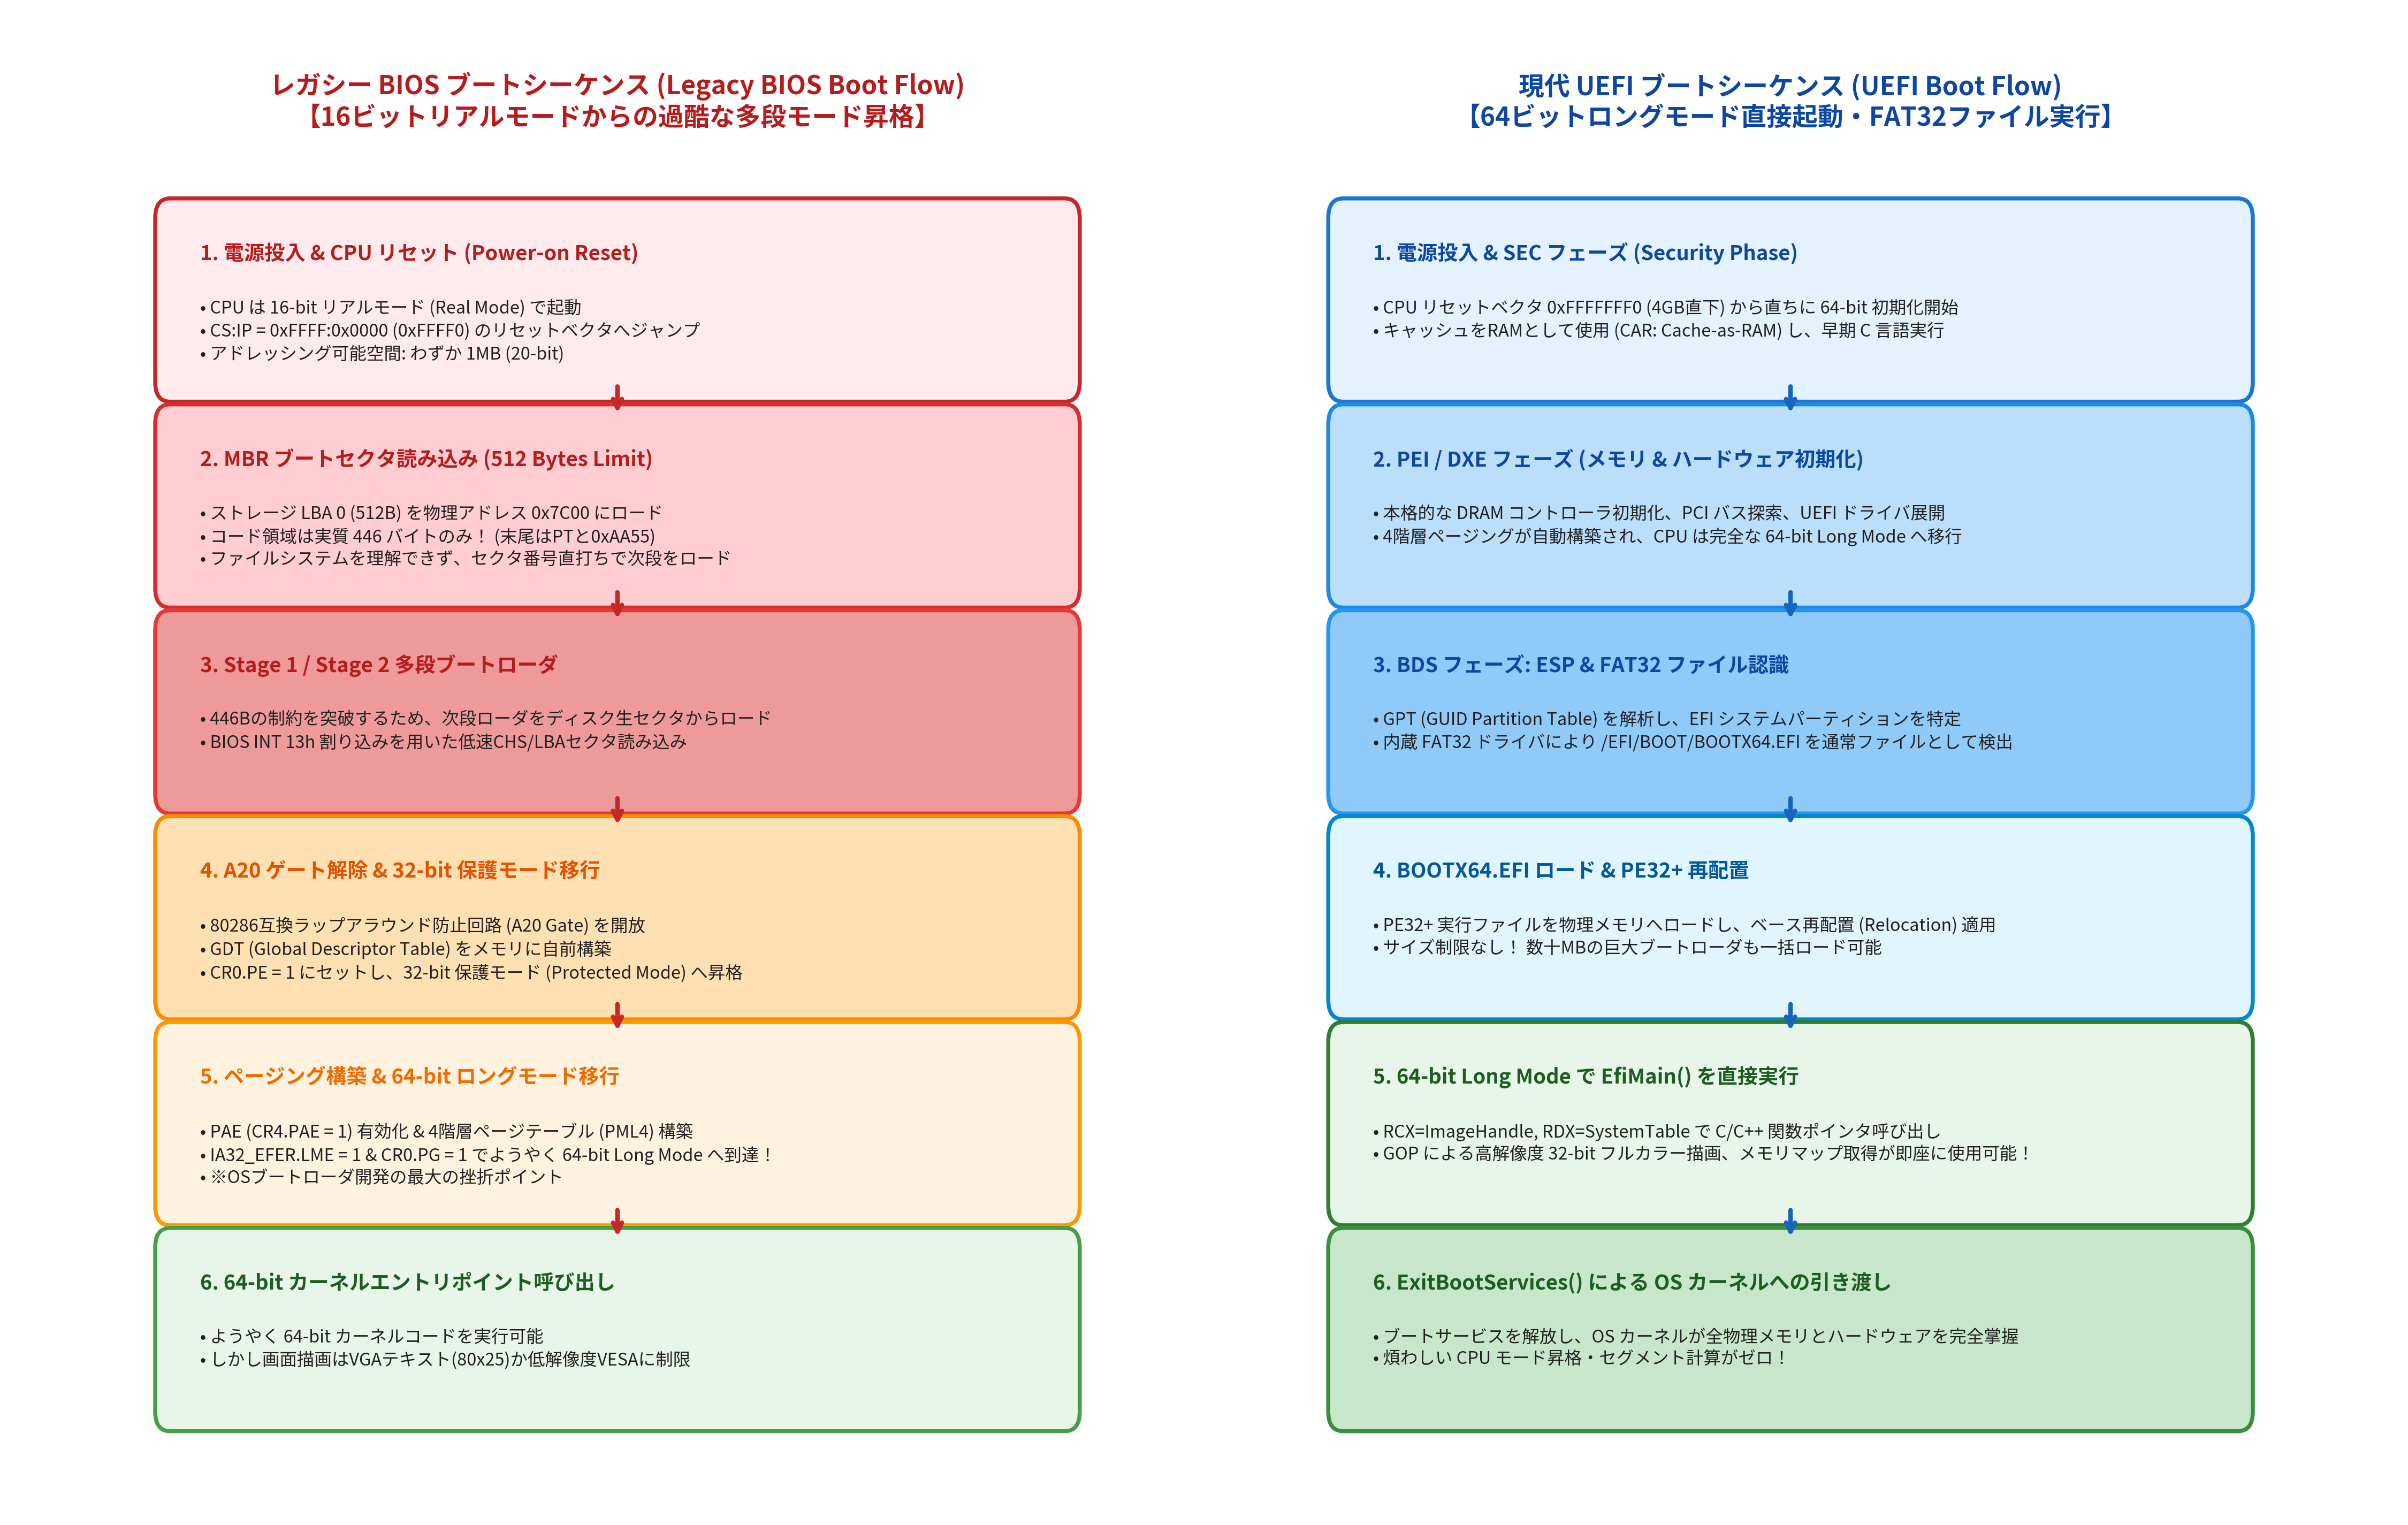

In [2]:
# 高解像度アーキテクチャ図版: レガシー BIOS ブートシーケンス vs 現代 UEFI ブートシーケンス
from common import plot_legacy_bios_vs_uefi_boot_flow
from IPython.display import Image, display

fig13_path = "result/fig1_13_legacy_bios_vs_uefi_boot_flow.png"
plot_legacy_bios_vs_uefi_boot_flow(fig13_path)
display(Image(fig13_path))


## 2. CPU動作モードの比較：過酷な多段モード昇格 vs 即時64ビットロングモード

### 2.1 レガシー BIOS ブートローダ開発の苦難（モード昇格の 5 大関門）

レガシー BIOS 環境で 64 ビット OS カーネルを起動しようとした場合、プログラマはアセンブリ言語で以下の過酷な 5 つのハードウェア初期化ステップを自前で実装しなければなりませんでした：

1. **A20 ゲートの開放 (*Enable A20 Gate*)**:
   - I/O ポート `0x92` のビット 1 をセット、またはキーボードコントローラコマンドを送信して 1MB 超のアドレス線を有効化。
2. **GDT (Global Descriptor Table) の自前構築と 32-bit 保護モード移行**:
   - コードセグメント・データセグメントのベースアドレス、リミット、特権レベル（DPL=0）を定義した GDT 構造体を物理メモリ上に構築。
   - `lgdt` 命令で GDT レジスタ（GDTR）にロード。
   - 制御レジスタ `CR0` の Protection Enable ビット（`CR0.PE` = bit 0）を `1` にセット。
   - ファージャンプ命令（`jmp 0x08:protected_entry`）を実行してプリフェッチキューをフラッシュし、32ビット保護モードへ突入。
3. **PAE (Physical Address Extension) の有効化**:
   - 制御レジスタ `CR4` の PAE ビット（`CR4.PAE` = bit 5）を `1` にセット。
4. **4階層ページテーブル (PML4) のメモリ確保と恒等マッピング**:
   - 64ビット Long Mode ではページングが**必須要件（強制）**です。
   - PML4、PDP、PD、PT の 4 階層ページテーブル（各 4KiB）をメモリ上に手動でゼロクリア・構築し、制御レジスタ `CR3` にベースアドレスを格納。
5. **MSR (Model Specific Register) 設定と 64-bit ロングモード移行**:
   - `IA32_EFER` MSR（アドレス `0xC0000080`）の Long Mode Enable ビット（`LME` = bit 8）を `wrmsr` 命令でセット。
   - `CR0` の Paging Enable ビット（`CR0.PG` = bit 31）を `1` にセット。
   - 64ビットコードセグメント記述子へファージャンプして、ようやく **64ビット Long Mode (IA-32e)** に到達！

> [!WARNING]
> 自作OS入門者の 8 割以上が、この「A20・GDT・ページング・モード移行」のアセンブリコード記述ミス（1ビットのフラグ誤りやスタック不整合で CPU トリプルフォルト → 即時再起動ループ）によって挫折してきました。

---

### 2.2 UEFI の革命的恩恵 (The UEFI Breakthrough)

UEFI ファームウェアは、OS ブートローダ（`BOOTX64.EFI`）の `EfiMain()` を呼び出す前に、マザーボード上の SEC → PEI → DXE フェーズを通じて、以下の環境構築を**完全に完了**させています：

- ✅ **CPU は起動直後から完全な 64ビットロングモード（Long Mode / IA-32e）**
- ✅ **全物理メモリが恒等マッピング（Identity Mapping: 物理アドレス == 仮想アドレス）された 4階層ページングが設定済み**
- ✅ **有効な 64ビットスタックポインタ（`RSP`）が潤沢なサイズで割り当て済み**
- ✅ **C言語 / C++20 の関数ポインタ呼び出し規約（Microsoft x64 ABI）がそのまま通用**

このため、MikanOS では第1章のハローワールドの時点から、面倒な 16ビットリアルモードや A20 ゲート、GDT、初期ページングのアセンブリコードを一切書くことなく、**いきなり 64ビットの世界で優雅にプログラミングを開始できる**のです。


In [3]:
# Python シミュレータによる 16ビットリアルモード・アドレス計算と A20 ラップアラウンド検証
from common import RealModeAddress

cases = [
    (0x0000, 0x7C00, "BIOS MBR ブートセクタ読み込みアドレス"),
    (0xFFFF, 0x0000, "x86 CPU リセットベクタ (CS:IP = 0xFFFF:0x0000)"),
    (0xFFFF, 0x0010, "1MB 境界完全一致ラップアラウンド検証 (0x100000)"),
    (0xFFFF, 0x0020, "1MB 超過アドレス検証 (0x100010)"),
]

print(f"{'Segment:Offset':<18} {'A20 Enabled':<16} {'A20 Disabled':<16} {'説明'}")
print("-" * 80)

for seg, off, desc in cases:
    addr_on = RealModeAddress(segment=seg, offset=off, a20_enabled=True)
    addr_off = RealModeAddress(segment=seg, offset=off, a20_enabled=False)

    flag_str = " [⚠️ 0x000000 にラップアラウンド！]" if addr_off.is_wrapped else ""
    print(f"0x{seg:04X}:0x{off:04X}     0x{addr_on.effective_address:06X}         0x{addr_off.effective_address:06X}         {desc}{flag_str}")


Segment:Offset     A20 Enabled      A20 Disabled     説明
--------------------------------------------------------------------------------
0x0000:0x7C00     0x007C00         0x007C00         BIOS MBR ブートセクタ読み込みアドレス
0xFFFF:0x0000     0x0FFFF0         0x0FFFF0         x86 CPU リセットベクタ (CS:IP = 0xFFFF:0x0000)
0xFFFF:0x0010     0x100000         0x000000         1MB 境界完全一致ラップアラウンド検証 (0x100000) [⚠️ 0x000000 にラップアラウンド！]
0xFFFF:0x0020     0x100010         0x000010         1MB 超過アドレス検証 (0x100010) [⚠️ 0x000000 にラップアラウンド！]


## 3. パーティション方式の革命：MBR vs GPT (*GUID Partition Table*)

現代の PC ストレージでは、MBR に代わり **GPT (*GUID Partition Table*)** が業界標準となっています。

### 3.1 MBR と GPT の仕様・数理比較

| 比較項目 | MBR (*Master Boot Record*) | GPT (*GUID Partition Table*) | 技術的背景・数理的根拠 |
|---|---|---|---|
| **LBA アドレッシング長** | **32 ビット** | **64 ビット** | MBR は $2^{32} \times 512\text{B} = 2.0\text{ TiB}$ 限界。GPT は $2^{64} \times 512\text{B} \approx 9.44\text{ ZB}$。 |
| **パーティション最大数** | **最大 4 個**（基本PT） | **標準 128 個以上** | MBR は拡張パーティションで誤魔化していたが、GPT は配列でフラットに 128 個を確保。 |
| **識別子 (Identifier)** | 1 バイトのパーティションタイプ（例: `0x0B`） | **128 ビット GUID** | 世界中で衝突しない一意な GUID により誤認識や競合を完全に排除。 |
| **冗長性・障害耐性** | **ゼロ**（先頭セクタ破損で即死） | **完全な二重化**（末尾バックアップ） | ディスク末尾に Backup GPT Header & Partition Array を保持し、CRC32 で自己修復。 |
| **保護用 MBR (Protective MBR)** | 自身が MBR そのもの | **LBA 0 にダミー配置** | GPT 非対応の古い OS やツールがディスク全体を空きディスクと誤認して破壊するのを防止。 |

### 3.2 保護用 MBR (Protective MBR) の賢明な設計

GPT フォーマットのディスクの **LBA 0** には、あえて古い MBR 形式に準拠した **Protective MBR** が書き込まれています。
そのパーティションテーブル（PT #1）には以下の値が設定されています：
- **パーティションタイプ**: `0xEE`（GPT 保護用パーティションを示す特殊コード）
- **開始 LBA**: `1`
- **セクタ数**: ディスク全体のサイズ（2TiB を超える場合は `0xFFFFFFFF`）

これにより、GPT を理解できないレガシーな OS や古いパーティション管理ソフトがこのディスクを読み込んでも、「ディスク全体が未知の単一パーティション `0xEE` で埋め尽くされている」と認識し、**大切な GPT データ領域を誤って上書きフォーマットしてしまう事故を防止**しています。


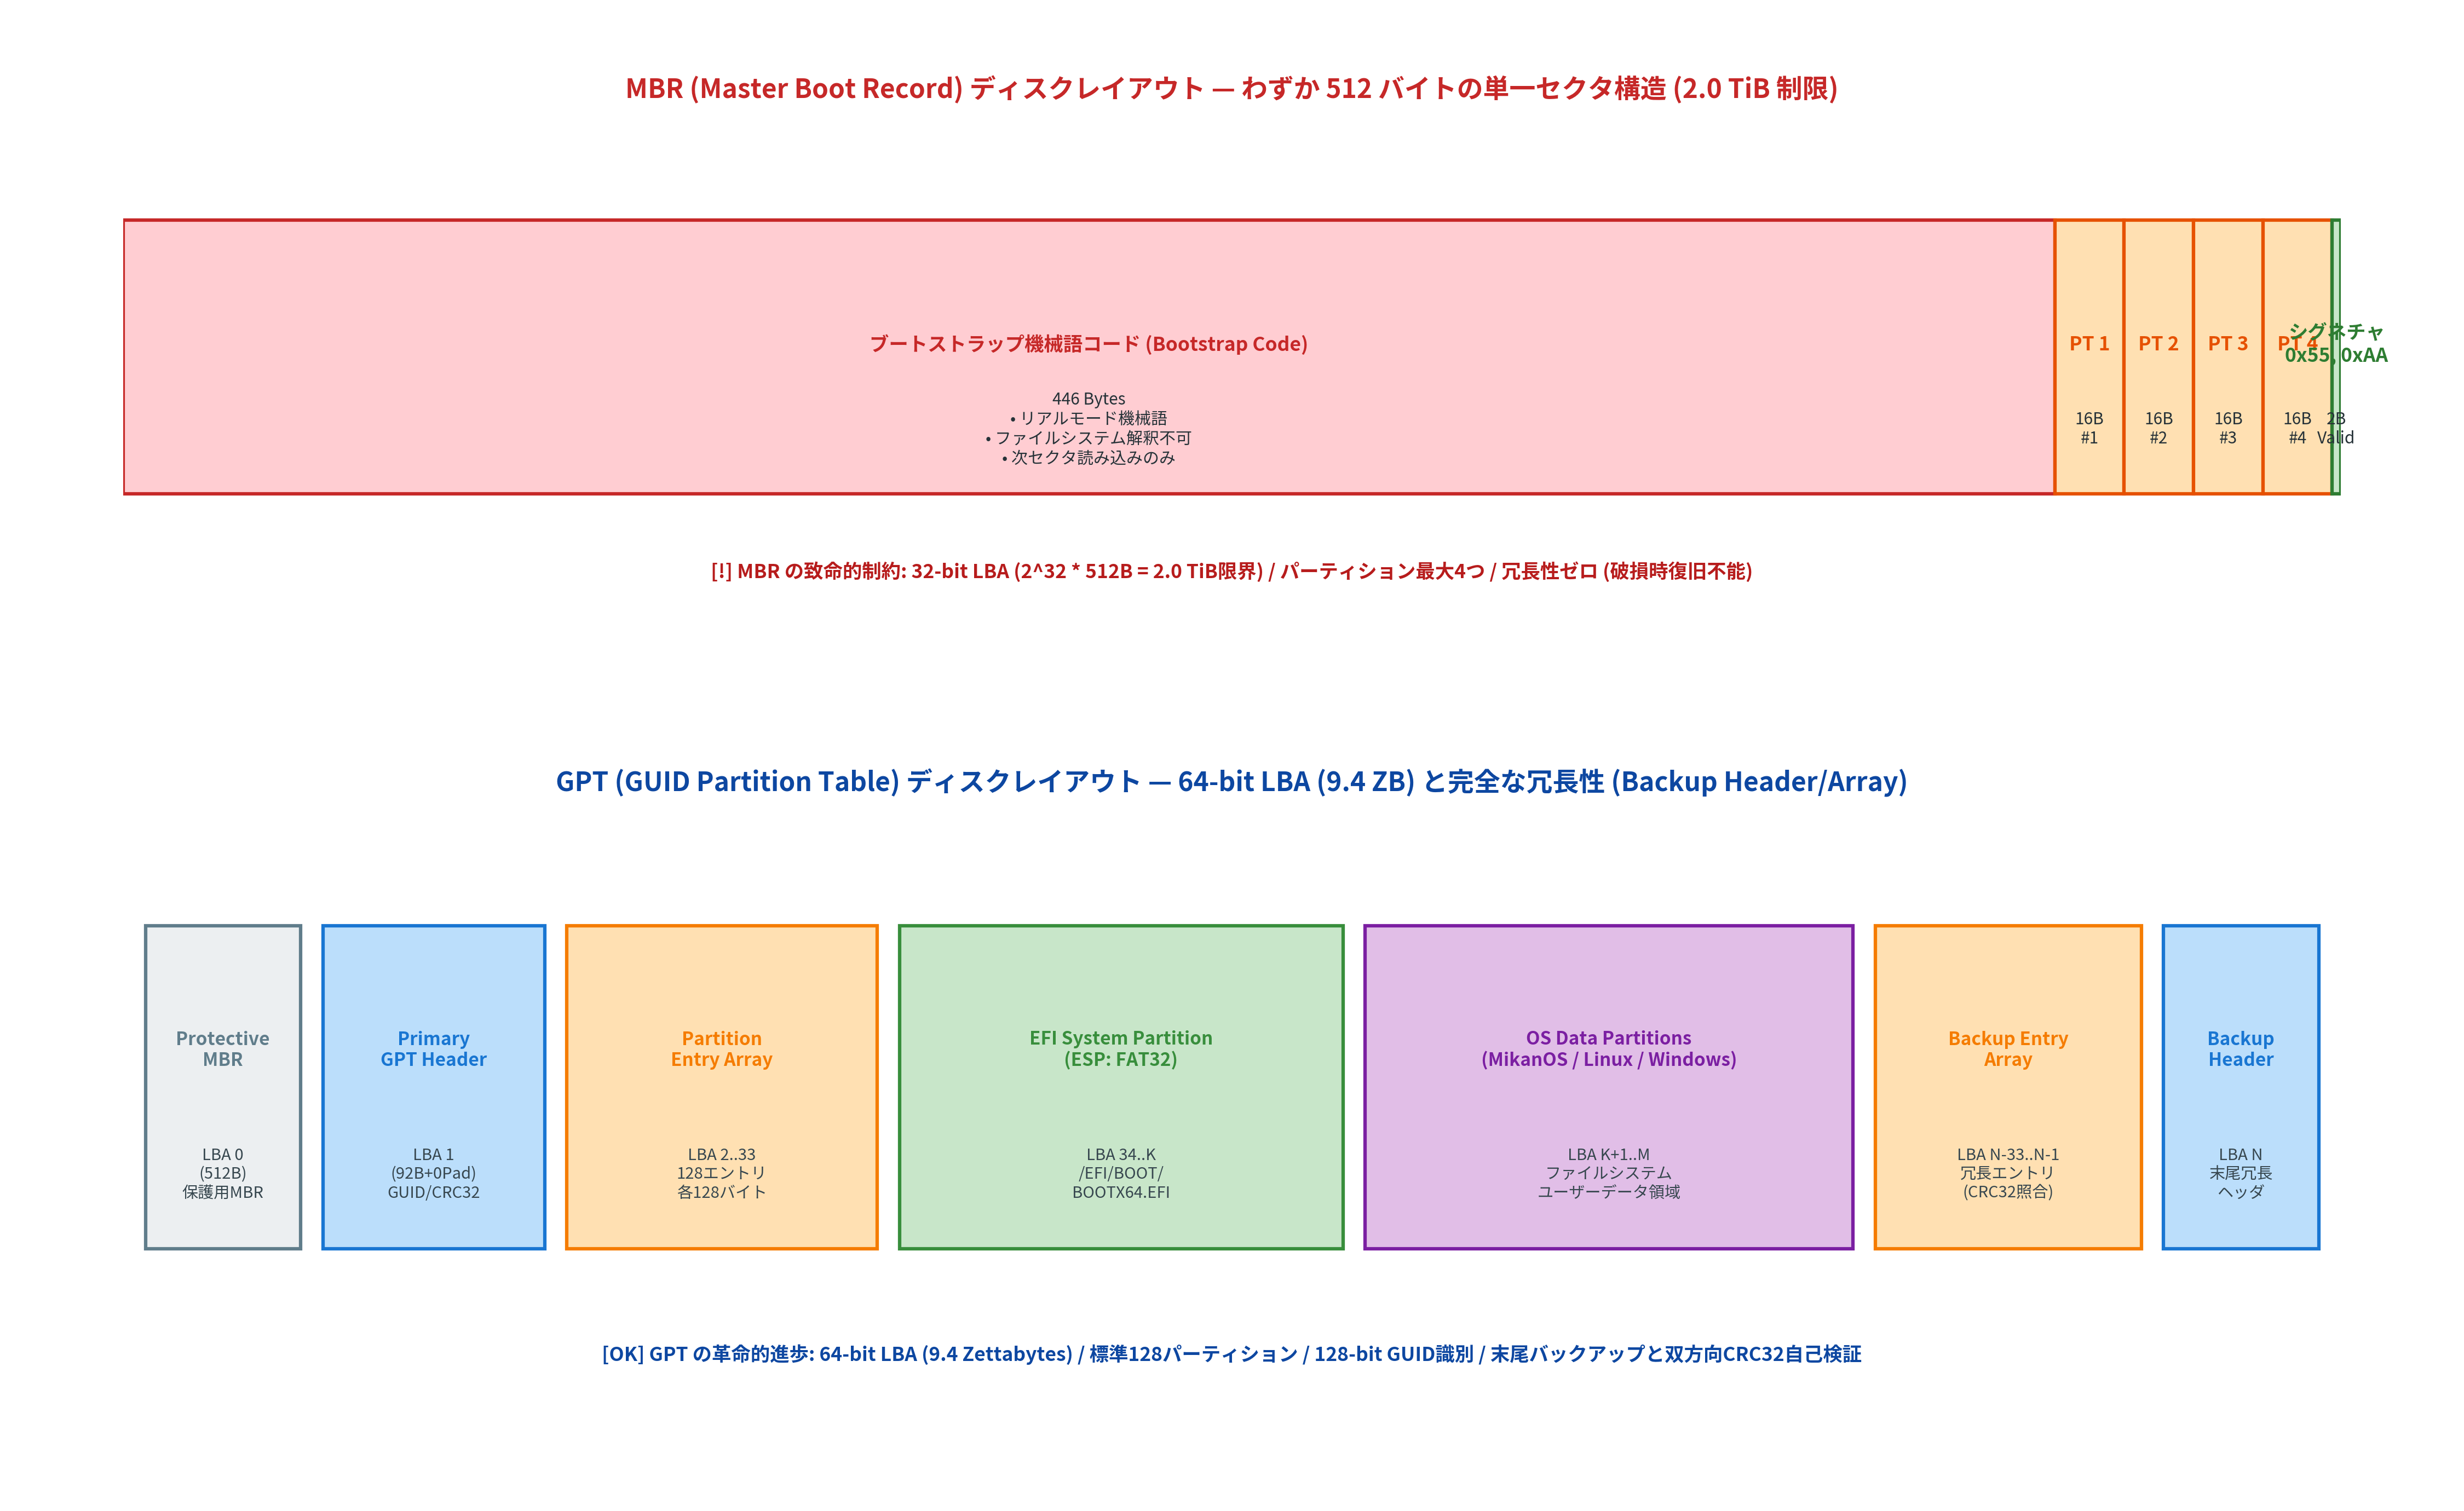

In [4]:
# 高解像度アーキテクチャ図版: MBR vs GPT ディスクレイアウトの完全解剖図
from common import plot_mbr_vs_gpt_disk_layout
from IPython.display import Image, display

fig14_path = "result/fig1_14_mbr_vs_gpt_disk_layout.png"
plot_mbr_vs_gpt_disk_layout(fig14_path)
display(Image(fig14_path))


## 4. UEFI システムサービスの2大分類：Boot Services vs Runtime Services

UEFI 仕様書（UEFI Specification）で定義されている API 群は、その**有効期間（ライフタイム）**によって厳密に 2 つに分類されます。
この設計こそが、OS カーネルがブートローダからシステム制御権を奪取するプロセスの美しさを支えています。

```mermaid
flowchart TD
    subgraph UEFI_Firmware["UEFI ファームウェア環境 (EfiMain 実行中)"]
        BS["ブートサービス (Boot Services / gBS)<br>• AllocatePages / FreePages (メモリ確保)<br>• GetMemoryMap (物理メモリ情報取得)<br>• GraphicsOutputProtocol (GOP解像度変更・描画)<br>• SimpleFileSystem / FileProtocol (ファイルI/O)<br>• タイマ・イベント待機"]
        RT["ランタイムサービス (Runtime Services / gRT)<br>• GetVariable / SetVariable (NVRAM不揮発変数)<br>• GetTime / SetTime (リアルタイムクロック RTC)<br>• ResetSystem (電源OFF・ハードウェア再起動)"]
    end

    EBS["ExitBootServices() 呼び出し<br>【OSへの制御権委譲の境界線】"]
    
    subgraph OS_Kernel["MikanOS カーネル実行中 (ExitBootServices 後)"]
        BS_DEAD["❌ ブートサービス消滅<br>（コード・データ領域は OS の空き物理メモリとして解放）"]
        RT_ALIVE["✅ ランタイムサービス存続<br>（カーネルから NVRAM や RTC、再起動を継続呼び出し可能）"]
        KERNEL_MEM["OS カーネルが物理メモリ・ページテーブル・割り込みを完全掌握！"]
    end

    BS --> EBS
    RT --> EBS
    EBS --> BS_DEAD
    EBS --> RT_ALIVE
    BS_DEAD --> KERNEL_MEM
```

### 4.1 ブートサービス (*Boot Services*) の役割と消滅
- **アクセス方法**: `gBS` ポインタ（`EFI_BOOT_SERVICES*`）
- **主要機能**:
  - メモリマップの取得（`gBS->GetMemoryMap`）
  - メモリ確保・解放（`gBS->AllocatePages`, `gBS->AllocatePool`）
  - GOP によるグラフィックス設定（`EFI_GRAPHICS_OUTPUT_PROTOCOL`）
  - ESP からのファイル読み込み（カーネルバイナリ `kernel.elf` のロード）
- **ライフタイム**: **OS が `ExitBootServices()` を呼び出すまでの間のみ有効**。
  - OS カーネルが自前でメモリ管理やタスク管理を行う準備が整ったら、`ExitBootServices()` を呼び出します。
  - これにより、ブートサービスが占有していた数MB〜数十MBのメモリ領域（`EfiBootServicesCode`, `EfiBootServicesData`）はすべて OS の**空きメモリ（Conventional Memory）として再利用可能**になります。

### 4.2 ランタイムサービス (*Runtime Services*) の役割と恒久性
- **アクセス方法**: `gRT` ポインタ（`EFI_RUNTIME_SERVICES*`）
- **主要機能**:
  - マザーボードの NVRAM 変数の読み書き（`gRT->GetVariable`, `gRT->SetVariable`）
  - ハードウェア時刻の取得・設定（`gRT->GetTime`, `gRT->SetTime`）
  - PC のシャットダウンやリセット（`gRT->ResetSystem`）
- **ライフタイム**: **OS 起動後も永続的に存続**。
  - OS カーネルが稼働中であっても、OS はファームウェアのランタイムサービスを呼び出して時刻合わせや電源オフを行えます。


In [5]:
# Python による GPT ヘッダおよび ESP (EFI System Partition) の解析シミュレーション
from common import GptHeader, GptPartitionEntry

# 1. 1TB NVMe SSD 上の GPT ヘッダ
gpt_hdr = GptHeader(
    current_lba=1,
    backup_lba=2000000000,
    first_usable_lba=34,
    last_usable_lba=1999999967,
    disk_guid="550E8400-E29B-41D4-A716-446655440000",
)

# 2. EFI システムパーティション (ESP) エントリ
esp = GptPartitionEntry(
    type_guid=GptPartitionEntry.ESP_TYPE_GUID,
    unique_guid="A0B1C2D3-E4F5-6789-0123-456789ABCDEF",
    starting_lba=2048,
    ending_lba=411647,  # 200 MiB
    attributes=0,
    name="EFI System Partition"
)

# 3. MikanOS データパーティション
data_part = GptPartitionEntry(
    type_guid=GptPartitionEntry.LINUX_DATA_GUID,
    unique_guid="B1C2D3E4-F5A6-7890-1234-56789ABCDEF0",
    starting_lba=411648,
    ending_lba=20480000,
    attributes=0,
    name="MikanOS System Root"
)

print(f"GPT Header Signature: {gpt_hdr.signature.decode('ascii')}")
print(f"Header Size         : {gpt_hdr.header_size} bytes")
print(f"64-bit Max Capacity : {GptHeader.max_addressable_capacity_zb():.2f} ZB")
print("-" * 65)

for part in [esp, data_part]:
    print(f"パーティション名: '{part.name}'")
    print(f"  - GUID      : {part.type_guid}")
    print(f"  - ESP 判定  : {'✅ ESP (UEFI ブート対象)' if part.is_esp else '通常データ領域'}")
    print(f"  - セクタ範囲: LBA {part.starting_lba} .. {part.ending_lba} ({part.sector_count:,} セクタ)")
    print(f"  - 容量      : {part.size_mib():.1f} MiB")


GPT Header Signature: EFI PART
Header Size         : 92 bytes
64-bit Max Capacity : 9.44 ZB
-----------------------------------------------------------------
パーティション名: 'EFI System Partition'
  - GUID      : C12A7328-F81F-11D2-BA4B-00A0C93EC93B
  - ESP 判定  : ✅ ESP (UEFI ブート対象)
  - セクタ範囲: LBA 2048 .. 411647 (409,600 セクタ)
  - 容量      : 200.0 MiB
パーティション名: 'MikanOS System Root'
  - GUID      : 0FC63DAF-8483-4772-8E79-3D69D8477DE4
  - ESP 判定  : 通常データ領域
  - セクタ範囲: LBA 411648 .. 20480000 (20,068,353 セクタ)
  - 容量      : 9799.0 MiB


## 5. C++20 スタンドアロン検証ツールによるバイナリ構造検証

MikanOS プロジェクトでは、ハードウェア仕様書やバイナリ規格の正しさを保証するため、C++20 の `static_assert` と構造体パッキング（`#pragma pack(push, 1)`）を用いた型安全な検証ツール（`src/ch01/bios_uefi_comparator.cpp`）を CMake ビルドターゲットとして管理しています。

- `sizeof(MbrPartitionEntry) == 16`
- `sizeof(MbrSector) == 512`
- `sizeof(GptHeader) == 92`
- `sizeof(GptEntry) == 128`

以下のセルで、この C++20 検証バイナリを直接実行し、アライメントと計算ロジックをホスト環境で実証します。


In [6]:
# C++20 スタンドアロン検証ツールの実行 (CMake ターゲット: ch01_bios_uefi_comparator)
!cmake --build ../build --target ch01_bios_uefi_comparator
!../build/bin/ch01_bios_uefi_comparator


[100%] Built target ch01_bios_uefi_comparator


  Chapter 1.7: Booting with UEFI BIOS Architectural Comparator   

[1] Low-Level Structure Size & Alignment Verification:
  - sizeof(MbrPartitionEntry) : 16 bytes (Expected: 16)
  - sizeof(MbrSector)         : 512 bytes (Expected: 512)
  - sizeof(GptHeader)         : 92 bytes (Expected: 92)
  - sizeof(GptEntry)          : 128 bytes (Expected: 128)
  -> All static assertions passed successfully!

[2] Real Mode Segment:Offset & A20 Gate Wraparound Simulation:
  Segment:Offset      A20 Enabled    A20 Disabled   Description
  ---------------------------------------------------------------------------
  0x0000:0x7C00  0x007C00        0x007C00        BIOS MBR Load Target (0x07C00)
  0xFFFF:0x0000  0x0FFFF0        0x0FFFF0        Reset Vector Base (0xFFFF0)
  0xFFFF:0x0010  0x100000        0x000000        1MB Boundary Exact Wrap Test (0x100000) [WRAPPED!]
  0xFFFF:0x0020  0x100010        0x000010        Above 1MB Boundary Test (0x100010) [WRAPPED!]

[3] Storage Addressing Limits (Sector Size 

## 6. 理解度セルフチェック演習（即時自己採点）

本節で学んだレガシー BIOS と UEFI の違い、CPU 動作モード、およびパーティション数理に関する重要概念をテストします。

### 問題一覧
1. **[Q1] リアルモードアドレス計算**:
   - セグメント `0x1000`、オフセット `0x0020` のとき、20ビット物理アドレスは `0x` 何になるか？（16進文字列で解答）
2. **[Q2] A20 ゲートのマスキング対象**:
   - A20 ゲートが無効（Disabled）のとき、ハードウェアによって強制的に 0 に落とされるアドレス線（ビット番号）は何番か？（整数で解答）
3. **[Q3] MBR のアドレッシング限界**:
   - 1セクタ 512 バイト、32 ビット LBA アドレッシングを採用する MBR の最大アドレッシング容量は何 TiB か？（小数で解答）
4. **[Q4] UEFI システムサービスの境界**:
   - ブートサービス（Boot Services）が消滅し、メモリ領域が OS の空きメモリとして解放されるきっかけとなる UEFI 関数呼び出しの名前は何か？（完全修飾名で解答）
5. **[Q5] GPT の保護用 MBR**:
   - GPT フォーマットのストレージの LBA 0 に配置され、古いツールによる誤破壊を防ぐ Protective MBR に設定されるパーティションタイプコード（16進数 1バイト）は何か？（例: `0xEE`）


In [7]:
# === 理解度セルフチェック演習（解答入力セル） ===
# ※下記の変数にご自身の解答を入力してセルを実行してください。

ans_q1_addr = "0x10020"    # Q1: 0x1000:0x0020 の物理アドレス (16進数文字列)
ans_q2_a20_bit = 20        # Q2: A20 ゲートが無効時にマスクされるビット番号 (0-indexed)
ans_q3_mbr_tib = 2.0       # Q3: MBR (512B * 2^32) の最大アドレッシング容量 (TiB)
ans_q4_ebs = "ExitBootServices" # Q4: ブートサービスを終了してOSへ制御を引き渡すAPI
ans_q5_protective_type = 0xEE   # Q5: Protective MBR のパーティションタイプ

# === 自動採点ロジック ===
score = 0
total = 5

# Q1 Check: (0x1000 << 4) + 0x0020 = 0x10000 + 0x0020 = 0x10020
if int(ans_q1_addr, 16) == 0x10020:
    print("✅ Q1 正解！: (0x1000 * 16) + 0x0020 = 0x10020 (65,568 バイト)")
    score += 1
else:
    print(f"❌ Q1 不正解: 入力値 {ans_q1_addr} (正解は 0x10020)")

# Q2 Check: Bit 20
if ans_q2_a20_bit == 20:
    print("✅ Q2 正解！: Bit 20 (21本目のアドレス線、重み 2^20 = 1MB) がマスクされます")
    score += 1
else:
    print(f"❌ Q2 不正解: 入力値 {ans_q2_a20_bit} (正解は 20)")

# Q3 Check: 2.0 TiB
if abs(ans_q3_mbr_tib - 2.0) < 1e-3:
    print("✅ Q3 正解！: 2^32 * 512B = 2,199,023,255,552 Bytes = 2.0 TiB")
    score += 1
else:
    print(f"❌ Q3 不正解: 入力値 {ans_q3_mbr_tib} (正解は 2.0)")

# Q4 Check: ExitBootServices
if ans_q4_ebs.strip() == "ExitBootServices":
    print("✅ Q4 正解！: gBS->ExitBootServices() によりブートサービスが解放されます")
    score += 1
else:
    print(f"❌ Q4 不正解: 入力値 {ans_q4_ebs} (正解は ExitBootServices)")

# Q5 Check: 0xEE
if ans_q5_protective_type == 0xEE:
    print("✅ Q5 正解！: 0xEE (GPT Protective Partition) によりディスク破壊を防ぎます")
    score += 1
else:
    print(f"❌ Q5 不正解: 入力値 {hex(ans_q5_protective_type)} (正解は 0xEE)")

print(f"\n🎯 得点: {score} / {total} ({(score/total)*100:.1f}%)")
assert score == total, "すべての問題に正解するまで復習しましょう！"
print("🎉 全問正解です！UEFI BIOS の起動メカニズムとアーキテクチャを完全にマスターしました！")


✅ Q1 正解！: (0x1000 * 16) + 0x0020 = 0x10020 (65,568 バイト)
✅ Q2 正解！: Bit 20 (21本目のアドレス線、重み 2^20 = 1MB) がマスクされます
✅ Q3 正解！: 2^32 * 512B = 2,199,023,255,552 Bytes = 2.0 TiB
✅ Q4 正解！: gBS->ExitBootServices() によりブートサービスが解放されます
✅ Q5 正解！: 0xEE (GPT Protective Partition) によりディスク破壊を防ぎます

🎯 得点: 5 / 5 (100.0%)
🎉 全問正解です！UEFI BIOS の起動メカニズムとアーキテクチャを完全にマスターしました！


## 7. 本節のまとめと次節（1.8 節「OSを作る道具」）への展望

### 本節で体得した重要知見
1. **16ビットリアルモードと A20 の歴史的呪縛**:
   - 8086 の 1MB 空間とセグメント方式（$16 \times \text{Segment} + \text{Offset}$）、および 80286 互換性のための A20 ゲートによるラップアラウンドのメカニズムを数理的に解明しました。
2. **MBR の物理的限界と GPT の進化**:
   - 512 バイトのブートセクタと 32-bit LBA による **2.0 TiB の壁** を導出し、64-bit LBA（**9.4 ZB**）・128 個のパーティション・末尾バックアップと Protective MBR を備えた GPT の圧倒的堅牢性を理解しました。
3. **UEFI がもたらした OS 自作の近代化**:
   - アセンブリでの過酷な多段モード昇格（A20 → GDT → 保護モード → PAE → ページング → ロングモード）が不要になり、起動直後から **64ビットロングモード・全メモリ恒等マッピング・C/C++呼び出し規約** で OS 開発を行える決定的な恩恵を実証しました。
4. **Boot Services と Runtime Services の美しい分離**:
   - OS が `ExitBootServices()` を呼び出すことで、ファームウェアのブートリソースをすべて OS の空き物理メモリとして接収し、カーネルがハードウェアを完全掌握できる制御フローを把握しました。

---

### 次節への展望：1.8 節「OSを作る道具」

第1章ではこれまで、機械語バイナリを手動編集してハローワールドを表示し、PC の起動シーケンスを観察してきました。
しかし、OS カーネルのような巨大なソフトウェアをすべて 16進数の手打ちバイナリで書くことは不可能です。

次節 **1.8 節「OSを作る道具」** では：
- **C言語 / C++ ソースコードを x86-64 機械語へと翻訳するクロスコンパイラ（Clang / LLVM）**
- **オブジェクトファイルを結合して実行可能バイナリを構築するリンカ（LLD）**
- **標準 C ライブラリや OS が存在しない過酷な環境で動くプログラムを作るための「フリースタンディング環境（Freestanding）」**

の仕組みを解き明かし、いよいよ自分自身の手で C 言語によるハローワールドをビルドする準備へと進みます！
